<a href="https://colab.research.google.com/github/amaradaw/CollabProjects/blob/main/Amara_pr%C3%A1ctica_2_3_teachable_machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

En esta práctica se debe exportar el modelo que se genera en Teachable Machine.

A la hora de exportar el modelo, se puede exportar para Tensorflow.

También viene un fragmento de código para usar el modelo:

```
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

```

**Tarea**: subir 3 imágenes propias (una clara, una ambigua, una que no pertenezca a ninguna categoría) y anotar qué predice y con qué confianza.

**¡Ojo! Hay que cargar una  versión anterior de Keras**

In [5]:
# forzar TensorFlow a usar el comportamiento clásico de Keras 2
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras

print("Versión de TensorFlow:", tf.__version__)
print("Versión de TF-Keras (Legacy):", keras.__version__)

try:
    # Cargamos el modelo utilizando el módulo de compatibilidad oficial tf_keras
    model = keras.models.load_model('keras_model.h5', compile=False)
    print("\n¡MODELO CARGADO CON ÉXITO!")
    model.summary()
except Exception as e:
    print(f"\nError al cargar: {e}")

Versión de TensorFlow: 2.21.0
Versión de TF-Keras (Legacy): 2.21.0

¡MODELO CARGADO CON ÉXITO!
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 1280)              410208    
                                                                 
 sequential_3 (Sequential)   (None, 3)                 128400    
                                                                 
Total params: 538608 (2.05 MB)
Trainable params: 524528 (2.00 MB)
Non-trainable params: 14080 (55.00 KB)
_________________________________________________________________


In [7]:
import tensorflow as tf
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

class_names = open("labels.txt", "r").readlines()
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
image = Image.open("imaagen1.jpeg").convert("RGB")
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image)
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 1s 983ms/step
Class: Class 2
Confidence Score: 0.9982844


In [8]:
# implementa la clasificación con la imagen que pertenece claramente a una categoría

import tensorflow as tf
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

class_names = open("labels.txt", "r").readlines()
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
image = Image.open("imaagen1.jpeg").convert("RGB")
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image)
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 0s 33ms/step
Class: Class 2
Confidence Score: 0.9982844


In [9]:
# implementa la clasificación con una imagen ambigua, que puede ser de cualquier categoría

import tensorflow as tf
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

class_names = open("labels.txt", "r").readlines()
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
image = Image.open("balon.jpeg").convert("RGB")
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image)
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 0s 31ms/step
Class: Class 1
Confidence Score: 0.64722604


In [10]:
# implementa la clasificación con una imagen sin ninguna categoría del modelo

import tensorflow as tf
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

class_names = open("labels.txt", "r").readlines()
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
image = Image.open("strawberry.jpg").convert("RGB")
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image)
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 0s 31ms/step
Class: Class 1
Confidence Score: 0.8447743


**¿Cómo se usa el modelo exportado? ¿Cómo se comporta?**

---



Para utilizar el modelo que he exportado desde Teachable Machine
1- Carga de archivos: Cargo el archivo de mi modelo (keras_Model.h5) mediante Keras y leo el fichero labels.txt para relacionar los índices numéricos con los nombres de las clases.

2- Cargo los archivos de mi teachable machine (keras_model.h5) , (lablels.txt) y 3 fotos

3- Abro la imagen elegida en el codigo , la primera imagen es clara de un mando , la segunda es ambigua de un balon y una tercera foto que es de strawberry

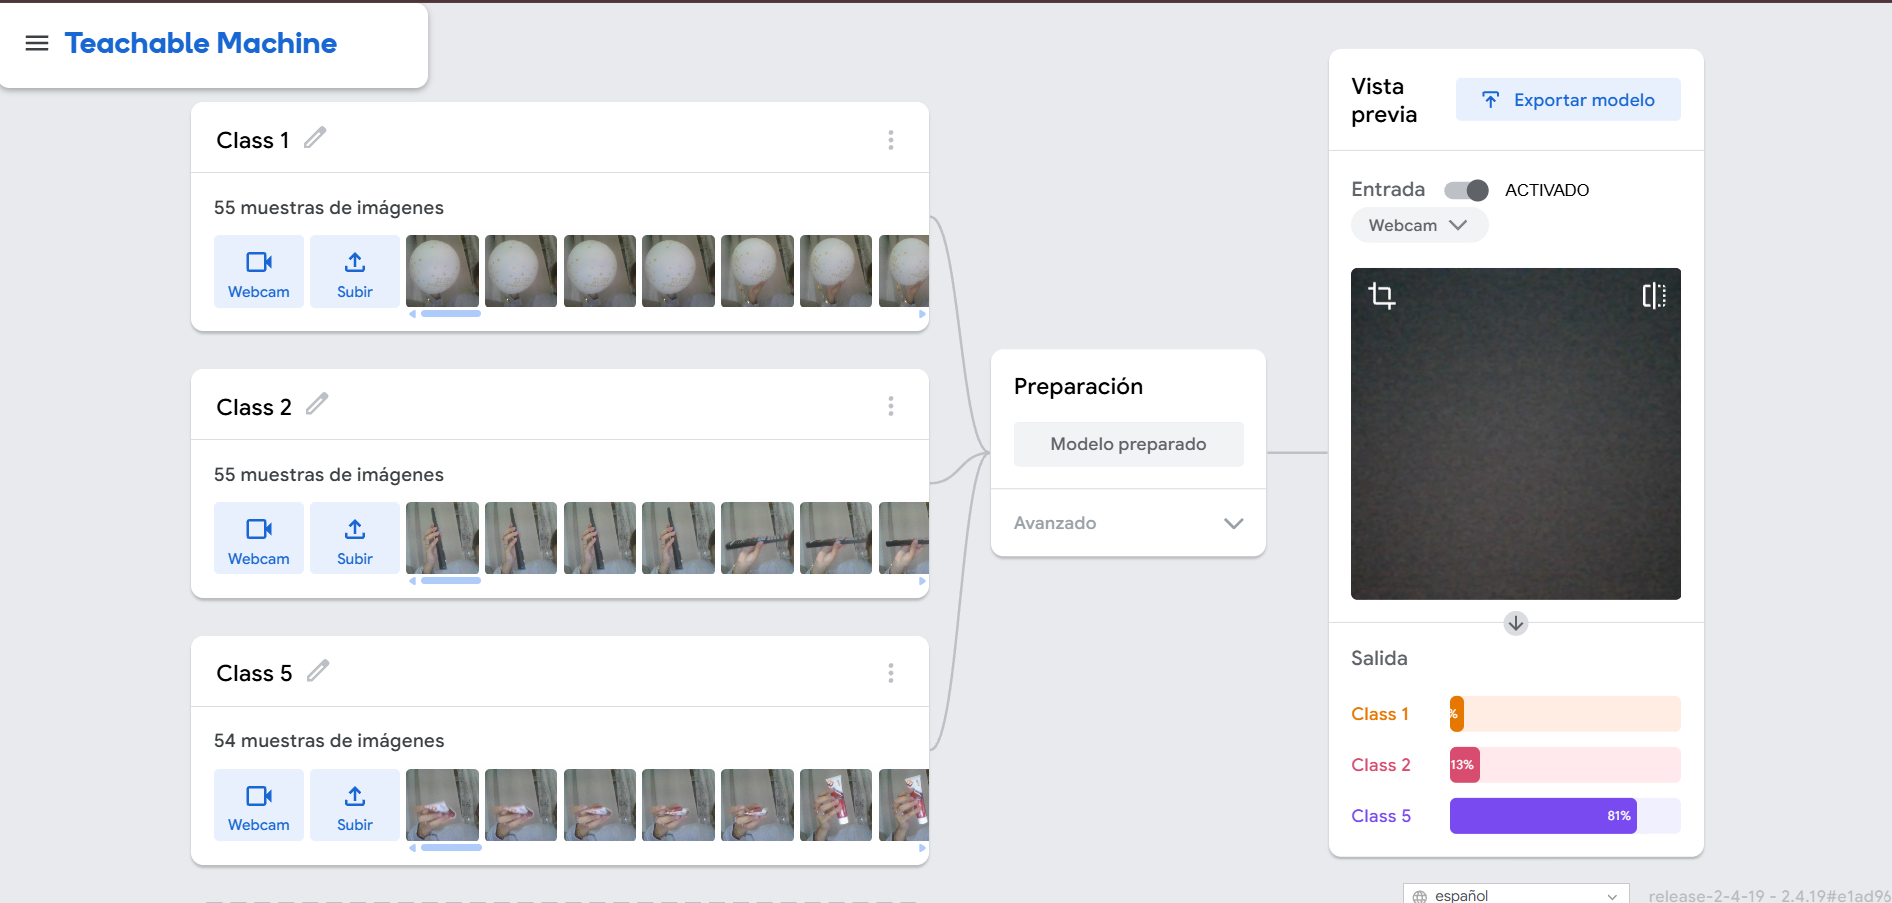

En las pruebas ejecutadas con mis imágenes, he observado los siguientes comportamientos
Si paso la misma imagen varias veces, el modelo devuelve exactamente la misma predicción y la misma probabilidad.

El modelo carece de una opción para indicar "desconocido". Si le introduzco una imagen que no pertenece a ninguna clase de entrenamiento, intentará asignarla a la categoría conocida que tenga bordes o colores parecidos, a menudo con una confianza alta.

Si el fondo de la imagen probada es muy distinto al fondo de mis fotos de entrenamiento, la confianza del modelo disminuye considerablemente.